# Reading a Nine-Quarter C&I Stress Scenario

**Evidence: Committed research evidence; Synthetic demonstration.** The first table
reads retained cumulative bank results. The later paths use a fictional bank and
artificial parameters supplied to the existing prediction interface. They are
not fitted estimates, official scenarios, or reconstructed historical paths.

**Research question:** how does a conditional macro path become quarterly and
cumulative C&I losses under a static balance sheet? Borrower conditions may
change the predicted rate, while fixed exposure translates that rate into dollars.
This calculation measures modeled sensitivity conditional on assumptions; it
does not assign a probability to the scenario.

[Previous: forecast evidence](02_benchmarks_and_forecast_evidence.ipynb) ·
[Project](../README.md) · [Reproduction](../docs/reproduction.md)

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from bankstress.research_guides import repository_root

ROOT = repository_root()
pd.set_option("display.max_columns", 8)
pd.set_option("display.width", 100)
plt.rcParams.update({"figure.figsize": (8, 3.4), "font.size": 10})

import yaml
from bankstress.stress import StressFit, recursive_stress_paths
from bankstress.research_guides import synthetic_ci_inputs
summary = json.loads((ROOT / "results/summary.json").read_text())
stress_spec = yaml.safe_load((ROOT / "configs/stress_specs.yaml").read_text())

## Fix the scope before adding losses

The configured jump-off is 2025Q4, followed by 2026Q1–2028Q1. Exposure and bank
controls are fixed at their jump-off values. We select only C&I, the two official
scenario labels, and AR mean or dynamic FE; researcher sensitivity scenarios must
not be counted again. Dollar amounts are retained unrounded in USD thousands.
Dividing by 1,000,000 displays USD billions. Different models are alternative
calculations, not positions to add together in a single portfolio.

In [2]:
jump_date = pd.Timestamp(stress_spec["stress"]["jump_off"])
quarters = pd.period_range(stress_spec["fed_2026"]["primary_start"], stress_spec["fed_2026"]["primary_end"], freq="Q")
assert str(jump_date.to_period("Q")) == "2025Q4"
assert len(quarters) == summary["stress_quarters"] == 9
assert quarters[0] == jump_date.to_period("Q") + 1
evidence = pd.read_csv(ROOT / "results/evidence/stress_by_bank.csv", dtype={"bank_id": str})
official = evidence.loc[evidence.segment.eq("CI") & evidence.scenario.isin(["baseline", "severely_adverse"])
                        & evidence.model.isin(["ar_mean", "dynamic_fe"])].copy()
assert not official.duplicated(["bank_id", "segment", "model", "scenario"]).any()
assert official.scenario_type.eq("Fed official").all()
assert official.cumulative_loss_thousands.notna().all()
groups = official.groupby(["model", "scenario"])
totals = groups.agg(banks=("bank_id", "nunique"), loss=("cumulative_loss_thousands", "sum"))
assert len(totals) == 4 and totals.banks.eq(summary["stress_banks"]).all()
bank_sets = groups.bank_id.agg(frozenset)
assert all(banks == bank_sets.iloc[0] for banks in bank_sets)
totals["loss"] /= 1_000_000
reference = pd.DataFrame(summary["ci_cumulative_loss_usd_billions"]).set_index(["model", "scenario"]).sort_index()
np.testing.assert_allclose(totals.loss, reference.loss, rtol=1e-12)
display(totals.rename(columns={"loss": "Cumulative loss (USD billions)"}).round(3))
print(f"Configured horizon: {quarters[0]} to {quarters[-1]}; jump-off: {jump_date.to_period('Q')}")

banks  Cumulative loss (USD billions)
model      scenario                                               
ar_mean    baseline             31                           5.402
           severely_adverse     31                           5.402
dynamic_fe baseline             31                           2.279
           severely_adverse     31                          12.287

Configured horizon: 2026Q1 to 2028Q1; jump-off: 2025Q4


AR contains no macro-scenario predictors, which explains its identical scenario
totals. Dynamic FE has a larger conditional response, but remains a **limited
challenger**: scenario sensitivity does not show that it predicts future losses
more accurately. The CSV records cumulative bank outcomes only. It cannot reveal
the timing of losses; dividing each total by nine would invent a flat path.
The following demonstration is deliberately independent of those totals.

## Supply transparent synthetic parameters

For `DEMO_CI`, the illustrative equation is
$$\widehat y_t=0.001+0.5\widehat y_{t-1}+0.1\,npl_0-0.002\,g_{t-1}.$$

The initial annualized rate is 0.02, current noncurrent-loan ratio is 0.03,
exposure is 1,000 USD thousands, and starting Tier 1 is 100 USD thousands.
GDP growth is expressed in percentage points. Both teaching paths share the
first origin-known GDP input; one then contracts. These are teaching assumptions,
not Federal Reserve values. The supplied columns already map the previous
quarter's macro input to the forecast quarter, so no second lag is applied.

In [3]:
jump, scenarios, models = synthetic_ci_inputs()
fit = models[0].fit_by_segment["CI"]
assert list(fit["entity_means"].index) == ["DEMO_CI::CI"]
display(Markdown("**Synthetic demonstration — parameter values supplied, not estimated.**"))
display(pd.Series(fit["beta"], index=fit["predictors"], name="Coefficient").to_frame())
display(Markdown("**Synthetic demonstration — GDP inputs (percentage points), already mapped to target quarter.**"))
display(scenarios.pivot(index="quarter", columns="scenario", values="lagged_gdp_growth"))
assert (scenarios.quarter.dt.to_period("Q") - 1).equals(scenarios.lagged_gdp_growth_source_quarter.dt.to_period("Q"))

**Synthetic demonstration — parameter values supplied, not estimated.**

,Coefficient
lagged_nco_rate,0.500
lagged_noncurrent_ratio,0.100
lagged_gdp_growth,-0.002


**Synthetic demonstration — GDP inputs (percentage points), already mapped to target quarter.**

scenario,synthetic_contraction,synthetic_mild
quarter,,
2026-03-31,2.0,2.0
2026-06-30,-3.0,2.0
2026-09-30,-3.0,2.0
2026-12-31,-2.0,2.0
2027-03-31,-1.0,2.0
2027-06-30,0.0,2.0
2027-09-30,1.0,2.0
2027-12-31,2.0,2.0
2028-03-31,2.0,2.0


The FE prediction interface requires the ordered `predictors`, matching `beta`,
and an `entity_means` row indexed by `DEMO_CI::CI`. Predictor means are artificial
zeros and the outcome mean supplies the teaching intercept. The jump-off carries
current `npl_rate`; the existing control-freezing function maps it into
`lagged_noncurrent_ratio`. No model-use registry is forged. We call the generic
recursive interface, leaving the formal historical model/segment gate intact.

In [4]:
paths = recursive_stress_paths(jump, scenarios, models)
paths = paths.sort_values(["scenario", "horizon"]).copy()
assert paths.groupby("scenario").horizon.apply(list).map(lambda h: h == list(range(1, 10))).all()
assert paths.exposure.eq(1000).all() and paths.scenario_type.eq("Synthetic demonstration").all()
for scenario, expected in [("synthetic_mild", [0.010, 0.005]), ("synthetic_contraction", [0.010, 0.015])]:
    first_two = paths.loc[paths.scenario.eq(scenario)].head(2).raw_predicted_nco_rate
    np.testing.assert_allclose(first_two, expected, atol=1e-15)
# Explanatory derived lag: the jump-off followed by the previous raw prediction.
paths["Derived previous raw rate"] = paths.groupby("scenario").raw_predicted_nco_rate.shift().fillna(jump.nco_rate.iloc[0])
paths["Cumulative loss"] = paths.groupby("scenario").predicted_loss.cumsum()
display(Markdown("**Synthetic demonstration — mild path; rates are annualized decimals; losses are USD thousands.**"))
display(paths.loc[paths.scenario.eq("synthetic_mild"), ["horizon", "Derived previous raw rate",
    "raw_predicted_nco_rate", "loss_rate_for_aggregation", "predicted_loss", "Cumulative loss"]].round(6))

**Synthetic demonstration — mild path; rates are annualized decimals; losses are USD thousands.**

,horizon,Derived previous raw rate,raw_predicted_nco_rate,loss_rate_for_aggregation,predicted_loss,Cumulative loss
9,1,0.020000,0.010000,0.010000,2.500000,2.500000
10,2,0.010000,0.005000,0.005000,1.250000,3.750000
11,3,0.005000,0.002500,0.002500,0.625000,4.375000
12,4,0.002500,0.001250,0.001250,0.312500,4.687500
13,5,0.001250,0.000625,0.000625,0.156250,4.843750
14,6,0.000625,0.000312,0.000312,0.078125,4.921875
15,7,0.000312,0.000156,0.000156,0.039062,4.960937
16,8,0.000156,0.000078,0.000078,0.019531,4.980469
17,9,0.000078,0.000039,0.000039,0.009766,4.990234


## Separate the recursive state from dollar aggregation

Quarterly loss is
$$\ell_t=\max(\widehat y_t,0)\,L_0/4,\qquad C_h=\sum_{t=1}^{h}\ell_t.$$

The factor of four reverses the target's annualization; it is not an arbitrary
stress scaling. A raw negative prediction remains the next quarter's lagged state.
Only dollar aggregation is floored. The checks below use a constant positive rate
with a hand-calculated loss, then a zero-intercept model with lag coefficient 0.5
and initial rate −0.02. Clipping the recursive state would fail the second check.

In [5]:
negative_fit = {"predictors": ["lagged_nco_rate"], "beta": np.array([0.5]),
                "entity_means": pd.DataFrame({"nco_rate": [0.0], "lagged_nco_rate": [0.0]}, index=["DEMO_CI::CI"])}
negative_model = StressFit("synthetic_negative_feedback", "fe", {"CI": negative_fit}, {"CI": ["lagged_nco_rate"]})
mild = scenarios.loc[scenarios.scenario.eq("synthetic_mild")]
negative = recursive_stress_paths(jump.assign(nco_rate=-0.02), mild, [negative_model])
np.testing.assert_allclose(negative.raw_predicted_nco_rate.head(2), [-0.01, -0.005])
assert negative.predicted_loss.eq(0).all()
positive_fit = {"predictors": ["lagged_nco_rate"], "beta": np.array([0.0]),
                "entity_means": pd.DataFrame({"nco_rate": [0.04], "lagged_nco_rate": [0.0]}, index=["DEMO_CI::CI"])}
positive_model = StressFit("synthetic_positive_units", "fe", {"CI": positive_fit}, {"CI": ["lagged_nco_rate"]})
positive = recursive_stress_paths(jump, mild, [positive_model])
np.testing.assert_allclose(positive.predicted_loss, 10.0)  # 0.04 / 4 * 1,000
display(Markdown("**Synthetic demonstration — negative feedback; losses in USD thousands.**"))
display(negative.head(2)[["horizon", "raw_predicted_nco_rate", "loss_rate_for_aggregation", "predicted_loss"]])

**Synthetic demonstration — negative feedback; losses in USD thousands.**

,horizon,raw_predicted_nco_rate,loss_rate_for_aggregation,predicted_loss
0,1,-0.010,0.0,0.0
1,2,-0.005,0.0,0.0


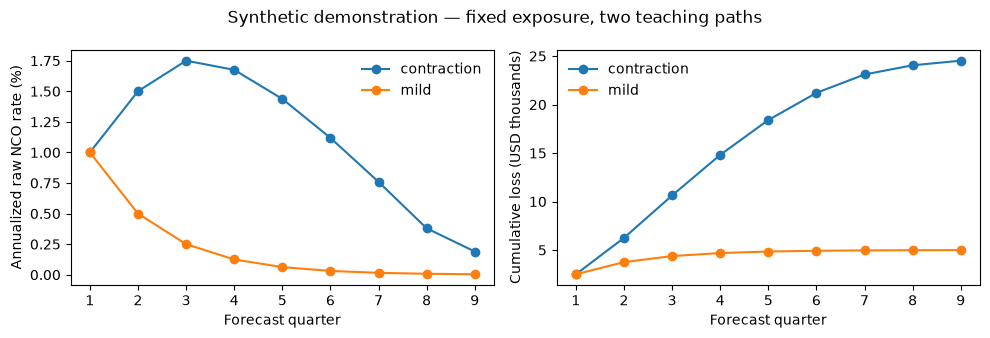

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for name, rows in paths.groupby("scenario"):
    label = name.removeprefix("synthetic_")
    axes[0].plot(rows.horizon, rows.raw_predicted_nco_rate * 100, marker="o", label=label)
    axes[1].plot(rows.horizon, rows["Cumulative loss"], marker="o", label=label)
axes[0].set(ylabel="Annualized raw NCO rate (%)", xlabel="Forecast quarter")
axes[1].set(ylabel="Cumulative loss (USD thousands)", xlabel="Forecast quarter")
for ax in axes:
    ax.set_xticks(range(1, 10))
    ax.legend(frameon=False)
fig.suptitle("Synthetic demonstration — fixed exposure, two teaching paths")
fig.tight_layout()
plt.show()

## Interpret burden without calling it capital depletion

Cumulative losses divided by starting Tier 1 measure modeled credit-loss burden.
They are not a capital roll-forward: earnings, provisions, taxes, distributions,
and risk-weighted-asset dynamics are absent. The denominator stays at its initial
value, just as exposure stays fixed. This is useful for interpreting scale under
declared assumptions, not for claiming regulatory capital adequacy or supervisory
approval. A deterministic conditional path also supplies no frequency or tail
probability for the realized future loss.

In [7]:
burden = paths.groupby("scenario").agg(cumulative_loss=("predicted_loss", "sum"),
                                       starting_tier1=("starting_tier1", "first"))
burden["modeled_credit_loss_burden"] = burden.cumulative_loss / burden.starting_tier1
display(Markdown("**Synthetic demonstration — monetary columns in USD thousands; burden is a decimal ratio.**"))
display(burden.round(6))

**Synthetic demonstration — monetary columns in USD thousands; burden is a decimal ratio.**

,cumulative_loss,starting_tier1,modeled_credit_loss_burden
scenario,,,
synthetic_contraction,24.525391,100.0,0.245254
synthetic_mild,4.990234,100.0,0.049902


The committed results support conditional C&I loss comparisons for the stated
models, horizon, and static assumptions. The synthetic paths explain recursion
and units; they provide no additional empirical evidence. One-step Q90 validation
does not authorize a multi-period tail distribution, and a larger stressed number
does not establish a better model. The separate model-risk extension has its own
conditional simulations and calibration limits; this guide neither reruns nor
upgrades those findings.

Next, inspect the [reproduction boundary](../docs/reproduction.md) before attempting
historical replay, or return to [data definitions](01_call_reports_to_credit_losses.ipynb)
and [benchmark evidence](02_benchmarks_and_forecast_evidence.ipynb).